In [1]:
# -------------------------------------------------------------------------
# 0. Clean & Safe Dependencies Installation
# -------------------------------------------------------------------------
!pip install -q transformers peft bitsandbytes accelerate evaluate rouge-score nltk scikit-learn seaborn matplotlib



   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 42.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 6.2 MB/s eta 0:00:00


Evaluation Compute Device: cuda
Scanning mounted directories in /kaggle/input...
  [Input Dir] /kaggle/input/notebooks/mikuchinu/mimic-cxr-model-4-train (10 files: ['optimal_thresholds.json', 'learning_curves.png', 'model4_qwen_best.pt', '__results__.html', 'model4_qwen_latest.pt'])
  [Input Dir] /kaggle/input/datasets/mikuchinu/mimic-cxr-model4-train-session1 (6 files: ['optimal_thresholds.json', 'learning_curves.png', 'model4_qwen_best.pt', 'model4_qwen_latest.pt', '__huggingface_repos__.json'])
  [Input Dir] /kaggle/input/datasets/mikuchinu/mimic-cxr-model4-prep-data (10 files: ['features_spatial_val.dat', 'mimic_master_split_with_rag.csv', 'features_spatial_train.dat', 'features_mean_train.dat', 'features_spatial_test.dat'])
Found Checkpoint        : /kaggle/input/notebooks/mikuchinu/mimic-cxr-model-4-train/model4_qwen_latest.pt
Found Test Spatial MMAP : /kaggle/input/datasets/mikuchinu/mimic-cxr-model4-prep-data/features_spatial_test.dat
Found Manifest CSV      : /kaggle/input/dat

config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

... (2 outputs left out)

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Model 4 Checkpoint loaded successfully from: /kaggle/input/notebooks/mikuchinu/mimic-cxr-model-4-train/model4_qwen_latest.pt
Starting Evaluation on all 6388 test cases...
[Test Eval 0100/6388 (  1.6%)] Elapsed: 5.5m | ETA: 346.3m | Avg BLEU-1: 0.1063
[Test Eval 0200/6388 (  3.1%)] Elapsed: 9.8m | ETA: 302.6m | Avg BLEU-1: 0.1210
[Test Eval 0300/6388 (  4.7%)] Elapsed: 15.4m | ETA: 311.8m | Avg BLEU-1: 0.1354
[Test Eval 0400/6388 (  6.3%)] Elapsed: 21.3m | ETA: 319.1m | Avg BLEU-1: 0.1415
[Test Eval 0500/6388 (  7.8%)] Elapsed: 26.3m | ETA: 310.1m | Avg BLEU-1: 0.1375
[Test Eval 0600/6388 (  9.4%)] Elapsed: 31.2m | ETA: 300.7m | Avg BLEU-1: 0.1422
[Test Eval 0700/6388 ( 11.0%)] Elapsed: 36.3m | ETA: 295.2m | Avg BLEU-1: 0.1369
[Test Eval 0800/6388 ( 12.5%)] Elapsed: 41.3m | ETA: 288.8m | Avg BLEU-1: 0.1445
[Test Eval 0900/6388 ( 14.1%)] Elapsed: 46.8m | ETA: 285.2m | Avg BLEU-1: 0.1406
[Test Eval 1000/6388 ( 15.7%)] Elapsed: 52.7m | ETA: 283.8m | Avg BLEU-1: 0.1371
[Test Eval 1100/6388 

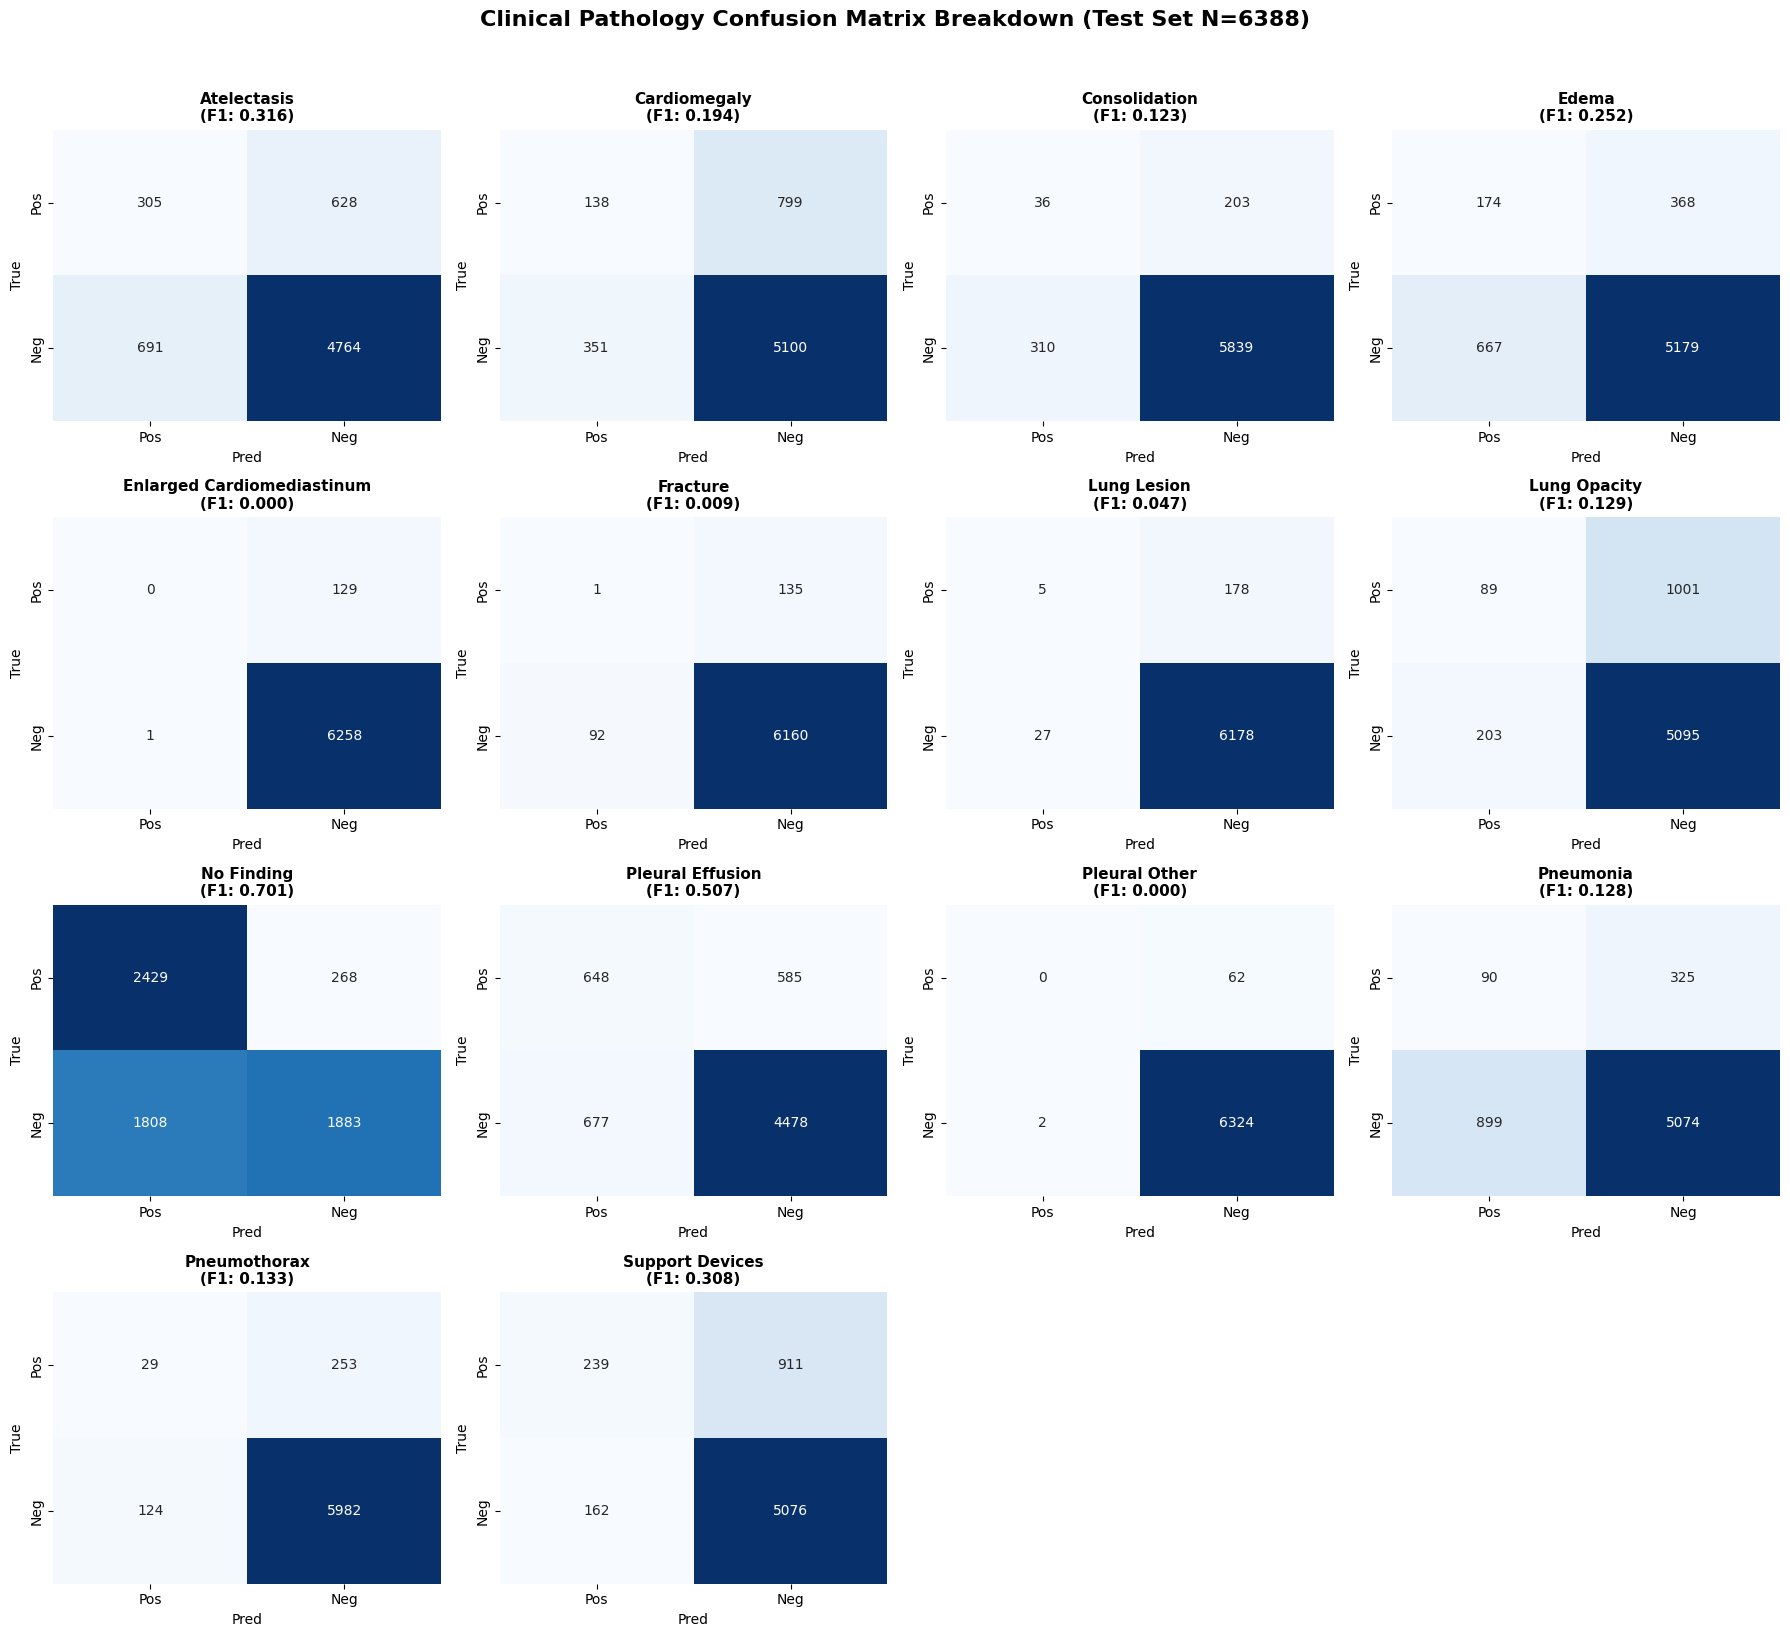

Confusion Matrices successfully saved to /kaggle/working/pathology_confusion_matrices.png

Evaluation completed in 325.3 minutes.
All Model 4 test artifacts, heatmaps and JSON/CSV reports saved successfully to /kaggle/working/


In [2]:
# -------------------------------------------------------------------------
# 1. Standalone Model 4 Evaluation: Auto-Discovery, True 4D Prefix Decoding, Full Benchmark
# -------------------------------------------------------------------------
import os, sys, math, random, time, re, json, torch, numpy as np, pandas as pd
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from transformers import (
    AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
)
from peft import LoraConfig, get_peft_model, set_peft_model_state_dict
from nltk.translate.bleu_score import sentence_bleu, corpus_bleu, SmoothingFunction
from rouge_score import rouge_scorer
from sklearn.metrics import f1_score, precision_score, recall_score, confusion_matrix
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Evaluation Compute Device: {device}", flush=True)

# -------------------------------------------------------------------------
# Auto-Locate Model 4 Artifacts (/kaggle/working or /kaggle/input)
# -------------------------------------------------------------------------
search_dirs = [
    Path("/kaggle/working"),
    Path("/kaggle/input")
]

print("Scanning mounted directories in /kaggle/input...", flush=True)
for root, dirs, files in os.walk("/kaggle/input", followlinks=True):
    if files:
        print(f"  [Input Dir] {root} ({len(files)} files: {files[:5]})")

candidate_ckpts = []
features_spatial_path = None
features_mean_path = None
manifest_path = None
thresholds_candidates = []

for base in search_dirs:
    if not base.exists():
        continue
    for root, _, files in os.walk(base, followlinks=True):
        for f in files:
            full = os.path.join(root, f)
            f_lower = f.lower()
            if "model4_qwen_best.pt" in f_lower or "model4_qwen_latest.pt" in f_lower:
                candidate_ckpts.append(full)
            elif "features_spatial_test.dat" in f_lower and features_spatial_path is None:
                features_spatial_path = full
            elif "features_mean_test.dat" in f_lower and features_mean_path is None:
                features_mean_path = full
            elif "mimic_master_split_with_rag.csv" in f_lower and manifest_path is None:
                manifest_path = full
            elif "optimal_thresholds.json" in f_lower:
                thresholds_candidates.append(full)

# Pick best checkpoint (highest epoch, prioritizing best.pt)
checkpoint_path = None
best_ckpt_meta = {"epoch": -1, "val_loss": float("inf")}

for cand in candidate_ckpts:
    try:
        temp_ckpt = torch.load(cand, map_location="cpu")
        ep = temp_ckpt.get("epoch", 1)
        vl = temp_ckpt.get("val_loss", float("inf"))
        is_best = "best.pt" in cand
        
        # Prioritize higher epoch and best.pt
        if (ep > best_ckpt_meta["epoch"]) or (ep == best_ckpt_meta["epoch"] and is_best):
            best_ckpt_meta = {"epoch": ep, "val_loss": vl}
            checkpoint_path = cand
    except Exception as e:
        if checkpoint_path is None:
            checkpoint_path = cand

thresholds_path = thresholds_candidates[-1] if thresholds_candidates else None

print(f"Found Checkpoint        : {checkpoint_path}", flush=True)
print(f"Found Test Spatial MMAP : {features_spatial_path}", flush=True)
print(f"Found Manifest CSV      : {manifest_path}", flush=True)

if not checkpoint_path or not features_spatial_path or not manifest_path:
    raise FileNotFoundError(
        "Missing required artifacts! Please ensure you added the output from the previous run "
        "via '+ Add Input' -> 'Your Work' -> 'mimic-cxr-model-4-ultimate-qwen'."
    )

enriched_df = pd.read_csv(manifest_path)
test_df = enriched_df[enriched_df["split"] == "test"].reset_index(drop=True)
n_test = len(test_df)
print(f"Loaded {n_test} test samples for benchmark evaluation.", flush=True)

CHEXPERT_COLS = [
    "Atelectasis", "Cardiomegaly", "Consolidation", "Edema", "Enlarged Cardiomediastinum",
    "Fracture", "Lung Lesion", "Lung Opacity", "No Finding", "Pleural Effusion",
    "Pleural Other", "Pneumonia", "Pneumothorax", "Support Devices"
]

# -------------------------------------------------------------------------
# Load Checkpoint & Auto-Detect Model Architecture (LoRA rank r=16 or r=32)
# -------------------------------------------------------------------------
print(f"Selected Best Checkpoint: {checkpoint_path}", flush=True)
ckpt = torch.load(checkpoint_path, map_location="cpu")
ckpt_epoch = ckpt.get("epoch", "unknown")
ckpt_loss = ckpt.get("val_loss", "unknown")
print(f"Checkpoint Metadata     : Epoch={ckpt_epoch} | Validation Loss={ckpt_loss}", flush=True)

# Auto-detect LoRA rank from state dict
detected_r = 32
for k, v in ckpt["lora_state"].items():
    if "lora_A" in k:
        detected_r = v.shape[0]
        break
detected_alpha = detected_r * 2
print(f"Auto-Configured Architecture: LoRA Rank r={detected_r}, Alpha={detected_alpha}", flush=True)

MODEL_NAME = "Qwen/Qwen2.5-3B-Instruct"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, trust_remote_code=True)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "right"

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=torch.float16
)

base_qwen = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    quantization_config=bnb_config,
    torch_dtype=torch.float16,
    device_map={"": 0},
    trust_remote_code=True
)

peft_config = LoraConfig(
    r=detected_r,
    lora_alpha=detected_alpha,
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM"
)
qwen_lora_model = get_peft_model(base_qwen, peft_config)

class MultiTaskQwenModel(nn.Module):
    def __init__(self, qwen_model, visual_dim=768, qwen_dim=2048, num_patches=128):
        super().__init__()
        self.qwen = qwen_model
        self.num_patches = num_patches
        self.qwen_dim = qwen_dim
        
        self.visual_projection = nn.Sequential(
            nn.Linear(visual_dim, qwen_dim),
            nn.GELU(),
            nn.Linear(qwen_dim, qwen_dim)
        ).to(device=device)
        
        self.classifier = nn.Sequential(
            nn.Linear(visual_dim, 512),
            nn.GELU(),
            nn.Dropout(0.2),
            nn.Linear(512, 14)
        ).to(device=device)
        
    def build_4d_prefix_attention_mask(self, batch_size, seq_len, device, dtype, text_pad_mask=None):
        total_len = self.num_patches + seq_len
        mask = torch.full((total_len, total_len), -10000.0, dtype=dtype, device=device)
        mask[:self.num_patches, :self.num_patches] = 0.0
        for i in range(self.num_patches, total_len):
            mask[i, :i+1] = 0.0
            
        mask_4d = mask.unsqueeze(0).unsqueeze(0).expand(batch_size, 1, total_len, total_len).clone()
        if text_pad_mask is not None:
            pad_expanded = text_pad_mask.unsqueeze(1).unsqueeze(2)
            mask_4d[:, :, :, self.num_patches:] = mask_4d[:, :, :, self.num_patches:].masked_fill(pad_expanded == 0, -10000.0)
        return mask_4d
        
    @torch.no_grad()
    def generate_report(self, spatial_token, retrieved_report, max_new_tokens=50, repetition_penalty=1.15, max_rag_tokens=40):
        self.eval()
        self.qwen.config.use_cache = True
        
        if spatial_token.dim() == 2:
            spatial_token = spatial_token.unsqueeze(0)
            
        visual_embeds = self.visual_projection(spatial_token.float())
        
        if pd.isna(retrieved_report) or str(retrieved_report).strip().lower() in ["", "nan", "none"]:
            retrieved_clean = "Normal chest radiograph with no acute cardiopulmonary abnormality."
        else:
            retrieved_clean = str(retrieved_report).strip()
            
        # Truncate RAG context cleanly
        rag_tokens = tokenizer.encode(retrieved_clean, add_special_tokens=False)[:max_rag_tokens]
        retrieved_clean = tokenizer.decode(rag_tokens, skip_special_tokens=True)
            
        messages = [
            {"role": "system", "content": "You are a professional radiologist assistant. Generate a concise, diagnostic chest X-ray findings impression report based on the image features and reference exemplar."},
            {"role": "user", "content": f"Reference Report:\n{retrieved_clean}\n\nGenerate the chest X-ray findings report:"}
        ]
        prompt_str = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
        prompt_enc = tokenizer(prompt_str, return_tensors="pt").to(device)
        prompt_ids = prompt_enc["input_ids"]
        prompt_embeds = self.qwen.get_input_embeddings()(prompt_ids)
        
        if visual_embeds.dtype != prompt_embeds.dtype:
            visual_embeds = visual_embeds.to(prompt_embeds.dtype)
            
        inputs_embeds = torch.cat([visual_embeds, prompt_embeds], dim=1)
        seq_len = prompt_ids.size(1)
        
        attention_mask_4d = self.build_4d_prefix_attention_mask(1, seq_len, spatial_token.device, inputs_embeds.dtype, prompt_enc["attention_mask"])
        
        prefill_out = self.qwen(
            inputs_embeds=inputs_embeds,
            attention_mask=attention_mask_4d,
            use_cache=True
        )
        past_key_values = prefill_out.past_key_values
        next_token_logits = prefill_out.logits[:, -1, :].clone()
        
        for token_id in set(prompt_ids[0].tolist()):
            if next_token_logits[0, token_id] > 0:
                next_token_logits[0, token_id] /= repetition_penalty
            else:
                next_token_logits[0, token_id] *= repetition_penalty
                
        curr_token = torch.argmax(next_token_logits, dim=-1, keepdim=True)
        generated_token_ids = [curr_token.item()]
        
        for _ in range(max_new_tokens - 1):
            if curr_token.item() in [tokenizer.eos_token_id, tokenizer.pad_token_id, 151645]:
                break
            step_out = self.qwen(
                input_ids=curr_token,
                past_key_values=past_key_values,
                use_cache=True
            )
            past_key_values = step_out.past_key_values
            next_logits = step_out.logits[:, -1, :].clone()
            
            for token_id in set(generated_token_ids):
                if next_logits[0, token_id] > 0:
                    next_logits[0, token_id] /= repetition_penalty
                else:
                    next_logits[0, token_id] *= repetition_penalty
                    
            curr_token = torch.argmax(next_logits, dim=-1, keepdim=True)
            generated_token_ids.append(curr_token.item())
            
        self.qwen.config.use_cache = False
        pred_text = tokenizer.decode(generated_token_ids, skip_special_tokens=True).strip()
        return pred_text

model = MultiTaskQwenModel(qwen_lora_model).to(device)

model.visual_projection.load_state_dict(ckpt["visual_projection"])
model.classifier.load_state_dict(ckpt["classifier"])
set_peft_model_state_dict(qwen_lora_model, ckpt["lora_state"])
model.eval()
print(f"Model 4 Checkpoint loaded successfully from: {checkpoint_path}", flush=True)

# -------------------------------------------------------------------------
# Robust Benchmark Evaluation with Live Step Logging
# -------------------------------------------------------------------------
test_spatial_mmap = np.memmap(features_spatial_path, dtype="float16", mode="r", shape=(n_test, 128, 768))

results = []
smooth = SmoothingFunction().method1
r_scorer = rouge_scorer.RougeScorer(['rouge1', 'rouge2', 'rougeL'], use_stemmer=True)

references = []
hypotheses = []

print(f"Starting Evaluation on all {n_test} test cases...", flush=True)
eval_start_time = time.time()

for i in range(n_test):
    row = test_df.iloc[i]
    spatial_t = torch.from_numpy(np.array(test_spatial_mmap[i])).to(device)
    retrieved_r = str(row["retrieved_report"]).strip()
    
    pred_text = model.generate_report(spatial_t, retrieved_r, max_new_tokens=50, repetition_penalty=1.15, max_rag_tokens=40)
    
    raw_gt = row['report']
    if pd.isna(raw_gt) or str(raw_gt).strip().lower() in ["", "nan", "none"]:
        gt_text = "Normal chest radiograph with no acute cardiopulmonary abnormality."
    else:
        gt_text = str(raw_gt).strip()
        
    gt_toks = gt_text.lower().split()
    pr_toks = pred_text.lower().split()
    
    references.append([gt_toks])
    hypotheses.append(pr_toks)
    
    b1 = sentence_bleu([gt_toks], pr_toks, weights=(1, 0, 0, 0), smoothing_function=smooth) if len(pr_toks) > 0 else 0.0
    b2 = sentence_bleu([gt_toks], pr_toks, weights=(0.5, 0.5, 0, 0), smoothing_function=smooth) if len(pr_toks) > 0 else 0.0
    b3 = sentence_bleu([gt_toks], pr_toks, weights=(0.33, 0.33, 0.33, 0), smoothing_function=smooth) if len(pr_toks) > 0 else 0.0
    b4 = sentence_bleu([gt_toks], pr_toks, weights=(0.25, 0.25, 0.25, 0.25), smoothing_function=smooth) if len(pr_toks) > 0 else 0.0
    
    rouge_res = r_scorer.score(gt_text, pred_text)
    r1 = rouge_res['rouge1'].fmeasure
    r2 = rouge_res['rouge2'].fmeasure
    rl = rouge_res['rougeL'].fmeasure
    
    res_dict = {
        "dicom_id": row["dicom_id"],
        "study_id": row["study_id"],
        "ground_truth": gt_text,
        "prediction": pred_text,
        "retrieved_prompt": retrieved_r,
        "bleu1": b1, "bleu2": b2, "bleu3": b3, "bleu4": b4,
        "rouge1": r1, "rouge2": r2, "rougeL": rl
    }
    for col in CHEXPERT_COLS:
        res_dict[f"gt_{col}"] = row[col]
    results.append(res_dict)
    
    if (i + 1) % 100 == 0 or (i + 1) == n_test:
        elapsed = time.time() - eval_start_time
        speed = (i + 1) / elapsed
        remaining = (n_test - (i + 1)) / speed if speed > 0 else 0
        pct = ((i + 1) / n_test) * 100.0
        print(f"[Test Eval {i+1:04d}/{n_test} ({pct:5.1f}%)] Elapsed: {elapsed/60:.1f}m | ETA: {remaining/60:.1f}m | Avg BLEU-1: {np.mean([r['bleu1'] for r in results]):.4f}", flush=True)
    if (i + 1) % 500 == 0:
        pd.DataFrame(results).to_csv("/kaggle/working/model4_qwen_test_predictions_interim.csv", index=False)

res_df = pd.DataFrame(results)
res_df.to_csv("/kaggle/working/model4_qwen_test_predictions.csv", index=False)

corpus_b1 = corpus_bleu(references, hypotheses, weights=(1, 0, 0, 0), smoothing_function=smooth)
corpus_b2 = corpus_bleu(references, hypotheses, weights=(0.5, 0.5, 0, 0), smoothing_function=smooth)
corpus_b3 = corpus_bleu(references, hypotheses, weights=(0.33, 0.33, 0.33, 0), smoothing_function=smooth)
corpus_b4 = corpus_bleu(references, hypotheses, weights=(0.25, 0.25, 0.25, 0.25), smoothing_function=smooth)

# -------------------------------------------------------------------------
# NegEx Medical Scope Parser
# -------------------------------------------------------------------------
print("Extracting Clinical Pathology Labels using NegEx Medical Scope Parser...", flush=True)

pathology_keywords = {
    "Atelectasis": ["atelectasis", "collapse", "atelectatic", "volume loss"],
    "Cardiomegaly": ["cardiomegaly", "enlarged heart", "heart is enlarged", "cardiac enlargement", "cardiac silhouette is enlarged"],
    "Consolidation": ["consolidation", "airspace disease", "air space disease", "infiltrate", "air bronchogram"],
    "Edema": ["edema", "pulmonary edema", "fluid overload", "vascular congestion", "chf", "heart failure", "vascular fullness"],
    "Enlarged Cardiomediastinum": ["enlarged cardiomediastinum", "widened mediastinum", "mediastinal widening"],
    "Fracture": ["fracture", "fractured", "broken rib", "callus formation", "deformity"],
    "Lung Lesion": ["nodule", "nodules", "mass", "masses", "lung lesion", "neoplasm", "granuloma"],
    "Lung Opacity": ["opacity", "opacities", "hazy", "haziness", "density", "densities", "infiltrate"],
    "No Finding": ["normal", "clear", "unremarkable", "within normal limits", "no acute cardiopulmonary", "no acute pulmonary", "no active disease"],
    "Pleural Effusion": ["pleural effusion", "effusion", "pleural fluid", "blunting of costophrenic", "fluid in pleural"],
    "Pleural Other": ["pleural thickening", "fibrothorax", "pleural plaque", "pleural calcification", "apical capping"],
    "Pneumonia": ["pneumonia", "infectious process", "bronchopneumonia"],
    "Pneumothorax": ["pneumothorax", "collapsed lung", "apical pneumothorax"],
    "Support Devices": ["tube", "catheter", "pacer", "pacemaker", "hardware", "drain", "wire", "sternotomy", "picc", "et tube"]
}

PRE_NEGATIONS = [
    r"\bno\b", r"\bwithout\b", r"\bnegative for\b", r"\bdenies\b",
    r"\bfree of\b", r"\bclear of\b", r"\bno evidence of\b", r"\bno sign of\b",
    r"\bno signs of\b", r"\brule out\b", r"\br/o\b", r"\babsent\b",
    r"\bunremarkable for\b", r"\bdisclosed no\b", r"\bno convincing\b"
]

POST_NEGATIONS = [
    r"\bunremarkable\b", r"\bwithin normal limits\b", r"\bruled out\b",
    r"\bnot seen\b", r"\bwas excluded\b", r"\bis excluded\b", r"\bresolved\b"
]

def extract_clinical_labels_negex(text_list):
    labels_dict = {col: [] for col in CHEXPERT_COLS}
    for text in text_list:
        text_lower = str(text).lower()
        sentences = re.split(r'[\.\;\n\!]', text_lower)
        sample_labels = {col: 0 for col in CHEXPERT_COLS}
        
        for sent in sentences:
            sent = sent.strip()
            if not sent:
                continue
                
            for col, kw_list in pathology_keywords.items():
                if col == "No Finding":
                    if any(kw in sent for kw in kw_list):
                        sample_labels[col] = 1
                else:
                    for kw in kw_list:
                        if kw in sent:
                            is_negated = False
                            for pre in PRE_NEGATIONS:
                                pattern = pre + r".{0,40}?\b" + re.escape(kw) + r"\b"
                                if re.search(pattern, sent):
                                    is_negated = True
                                    break
                            if not is_negated:
                                for post in POST_NEGATIONS:
                                    pattern = r"\b" + re.escape(kw) + r"\b.{0,30}?" + post
                                    if re.search(pattern, sent):
                                        is_negated = True
                                        break
                            if not is_negated:
                                sample_labels[col] = 1
                                break
                                
        for col in CHEXPERT_COLS:
            labels_dict[col].append(sample_labels[col])
            
    return pd.DataFrame(labels_dict)

pred_labels_df = extract_clinical_labels_negex(res_df["prediction"].tolist())

y_true = res_df[[f"gt_{c}" for c in CHEXPERT_COLS]].values
y_pred = pred_labels_df[CHEXPERT_COLS].values

macro_f1_all14 = f1_score(y_true, y_pred, average="macro", zero_division=0)
core10_indices = [CHEXPERT_COLS.index(c) for c in CHEXPERT_COLS if c not in ["Enlarged Cardiomediastinum", "Fracture", "Pleural Other"]]
macro_f1_core10 = f1_score(y_true[:, core10_indices], y_pred[:, core10_indices], average="macro", zero_division=0)
micro_f1 = f1_score(y_true, y_pred, average="micro", zero_division=0)
micro_prec = precision_score(y_true, y_pred, average="micro", zero_division=0)
micro_rec = recall_score(y_true, y_pred, average="micro", zero_division=0)

all_bigrams = []
for p in res_df["prediction"]:
    words = str(p).lower().split()
    if len(words) >= 2:
        all_bigrams.extend([f"{words[j]} {words[j+1]}" for j in range(len(words)-1)])
distinct_2 = len(set(all_bigrams)) / max(len(all_bigrams), 1)

# -------------------------------------------------------------------------
# Save Structured Benchmark Reports (JSON & CSV)
# -------------------------------------------------------------------------
benchmark_metrics = {
    "model_name": "Model 4 (RAD-DINO + Qwen-2.5-3B + QLoRA + RAG)",
    "sentence_bleu1": float(res_df['bleu1'].mean()),
    "sentence_bleu2": float(res_df['bleu2'].mean()),
    "sentence_bleu3": float(res_df['bleu3'].mean()),
    "sentence_bleu4": float(res_df['bleu4'].mean()),
    "corpus_bleu1": float(corpus_b1),
    "corpus_bleu2": float(corpus_b2),
    "corpus_bleu3": float(corpus_b3),
    "corpus_bleu4": float(corpus_b4),
    "rouge1": float(res_df['rouge1'].mean()),
    "rouge2": float(res_df['rouge2'].mean()),
    "rougeL": float(res_df['rougeL'].mean()),
    "distinct_2": float(distinct_2),
    "clinical_macro_f1_all14": float(macro_f1_all14),
    "clinical_macro_f1_core10": float(macro_f1_core10),
    "clinical_micro_f1": float(micro_f1),
    "clinical_micro_precision": float(micro_prec),
    "clinical_micro_recall": float(micro_rec)
}

with open("/kaggle/working/test_metrics.json", "w", encoding="utf-8") as f:
    json.dump(benchmark_metrics, f, indent=2)

pathology_rows = []
for idx, col in enumerate(CHEXPERT_COLS):
    yt = y_true[:, idx]
    yp = y_pred[:, idx]
    f1 = f1_score(yt, yp, zero_division=0)
    prec = precision_score(yt, yp, zero_division=0)
    rec = recall_score(yt, yp, zero_division=0)
    tp = int(((yp == 1) & (yt == 1)).sum())
    fp = int(((yp == 1) & (yt == 0)).sum())
    fn = int(((yp == 0) & (yt == 1)).sum())
    tn = int(((yp == 0) & (yt == 0)).sum())
    flag = "Low Sample (N < 150)" if yt.sum() < 150 else "OK"
    pathology_rows.append({
        "pathology": col,
        "true_positives": tp,
        "false_positives": fp,
        "false_negatives": fn,
        "true_negatives": tn,
        "precision": prec,
        "recall": rec,
        "f1_score": f1,
        "sample_flag": flag
    })

pathology_breakdown_df = pd.DataFrame(pathology_rows)
pathology_breakdown_df.to_csv("/kaggle/working/pathology_breakdown.csv", index=False)

print("\n" + "="*80, flush=True)
print("OVERALL BENCHMARK: Ultimate Model 4 (RAD-DINO + Qwen-2.5-3B-Instruct + QLoRA)", flush=True)
print("="*80, flush=True)
print(f"Sentence BLEU-1                | {benchmark_metrics['sentence_bleu1']:.4f}", flush=True)
print(f"Sentence BLEU-2                | {benchmark_metrics['sentence_bleu2']:.4f}", flush=True)
print(f"Sentence BLEU-3                | {benchmark_metrics['sentence_bleu3']:.4f}", flush=True)
print(f"Sentence BLEU-4                | {benchmark_metrics['sentence_bleu4']:.4f}", flush=True)
print(f"Corpus BLEU-1 (NIST)           | {benchmark_metrics['corpus_bleu1']:.4f}", flush=True)
print(f"Corpus BLEU-2 (NIST)           | {benchmark_metrics['corpus_bleu2']:.4f}", flush=True)
print(f"Corpus BLEU-3 (NIST)           | {benchmark_metrics['corpus_bleu3']:.4f}", flush=True)
print(f"Corpus BLEU-4 (NIST)           | {benchmark_metrics['corpus_bleu4']:.4f}", flush=True)
print(f"ROUGE-1                        | {benchmark_metrics['rouge1']:.4f}", flush=True)
print(f"ROUGE-2                        | {benchmark_metrics['rouge2']:.4f}", flush=True)
print(f"ROUGE-L                        | {benchmark_metrics['rougeL']:.4f}", flush=True)
print(f"Distinct-2                     | {benchmark_metrics['distinct_2']:.4f}", flush=True)
print(f"Clinical_Macro_F1_All14        | {benchmark_metrics['clinical_macro_f1_all14']:.4f}", flush=True)
print(f"Clinical_Macro_F1_Core10       | {benchmark_metrics['clinical_macro_f1_core10']:.4f}", flush=True)
print(f"Clinical_Micro_F1              | {benchmark_metrics['clinical_micro_f1']:.4f}", flush=True)
print(f"Clinical_Micro_Precision       | {benchmark_metrics['clinical_micro_precision']:.4f}", flush=True)
print(f"Clinical_Micro_Recall          | {benchmark_metrics['clinical_micro_recall']:.4f}", flush=True)
print("="*80, flush=True)

print("\n" + "="*110, flush=True)
print("PER-PATHOLOGY CLINICAL BREAKDOWN: Model 4 Qwen-3B (Proposal N >= 150 Threshold Flagging)", flush=True)
print("="*110, flush=True)
for r in pathology_rows:
    print(f"{r['pathology']:<26} | {r['true_positives']:<5} | {r['false_positives']:<5} | {r['false_negatives']:<5} | {r['true_negatives']:<5} | {r['precision']:.4f}  | {r['recall']:.4f}  | {r['f1_score']:.4f}  | [{r['sample_flag']}]", flush=True)

# -------------------------------------------------------------------------
# Plot & Save Pathology Confusion Heatmaps
# -------------------------------------------------------------------------
fig, axes = plt.subplots(4, 4, figsize=(18, 16))
axes = axes.flatten()

for idx, col in enumerate(CHEXPERT_COLS):
    cm = confusion_matrix(y_true[:, idx], y_pred[:, idx], labels=[1, 0])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[idx],
                xticklabels=["Pos", "Neg"], yticklabels=["Pos", "Neg"])
    f1_val = pathology_rows[idx]['f1_score']
    axes[idx].set_title(f"{col}\n(F1: {f1_val:.3f})", fontsize=11, fontweight="bold")
    axes[idx].set_ylabel("True")
    axes[idx].set_xlabel("Pred")

for idx in range(len(CHEXPERT_COLS), len(axes)):
    fig.delaxes(axes[idx])

plt.suptitle("Clinical Pathology Confusion Matrix Breakdown (Test Set N=6388)", fontsize=16, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("/kaggle/working/pathology_confusion_matrices.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()
print("Confusion Matrices successfully saved to /kaggle/working/pathology_confusion_matrices.png", flush=True)

print(f"\nEvaluation completed in {(time.time()-eval_start_time)/60:.1f} minutes.", flush=True)
print("All Model 4 test artifacts, heatmaps and JSON/CSV reports saved successfully to /kaggle/working/", flush=True)

